# 02 · Исправленная вложенная проверка и Grid Search · v2
## tl;dr
Выполнен полный поиск **630 сочетаний** с тремя внутренними оценками и пятью внешними фолдами. Лидер по среднему внешнему macro-F1: **C_ovr**, **0.8744**. Shortlist: **C_ovr/single, D_hierarchy/single**. Калибровка/порог выбирались внутри внешней обучающей части; баланс учитывает независимые записи каждого класса. История сохранена в `history/v1/`.

## Context & Methods

Цель — предсказание экспертного NSP, а не исхода ребёнка. Все 1360 исходных train-сегментов сохранены; validation/test не участвуют в этом ноутбуке. Нет идентификатора пациентки: исходный файл — доступная единица группировки.

### Key Assumptions

- Общие 5 внешних × 3 внутренних фолда. Детерминированное распределение файлов балансирует для каждого NSP и число сегментов, и присутствие класса в исходных файлах. Размеры крупных файлов могут мешать одинаковым долям строк. Фолды не подбираются по признакам или качеству модели.
- A: MultiClass, B: SqrtBalanced и Balanced, C: три OvR, D: abnormal и conditional pathologic, плюс логистика. Полный grid CatBoost: depth=3/5/7, iterations=300/600, learning_rate=.03/.1, L2=3/10; логистика C=.1/1/10 × None/Balanced. Итого 630 сочетаний «семейство × внешний фолд × параметры», по три внутренних оценки.
- Поиск деревьев использует средний внутренний macro-F1. Затем **внутри той же внешней обучающей части** выбираются калибровка и политика порога. Внешний holdout оценивает уже всю процедуру. Выбор конкретных параметров по raw score — явно заданная двухэтапная процедура, не глобальная совместная оптимизация всех возможных настроек.
- Калибровка: без изменения / scalar temperature / отдельные sigmoid по трём вероятностям с нормировкой. Метод выбирается по cross-fitted log loss, proper probability score. Для OvR калибровка не навязывается, если ухудшает log loss. Порог патологии оценивается отдельно по cross-fit macro-F1 и принимается при выигрыше ≥.005. Финальный порог на fit-стороне обучается по cross-fitted вероятностям.
- Внешний test-фолд не используется для scaler fit, калибровки, порогов или early stopping. Логистика клонирует и заново обучает подготовку внутри каждого fit. CatBoost использует исходные измерения без скейлера; DS/Width исключены, Tendency категориальная. Веса классов не дублируются.
- Основная метрика остаётся segment macro-F1. Дополнительно: recall/AP патологии, log loss и file-balanced метрики (сначала равновероятный файл, затем сегмент внутри него). Они отвечают разным вопросам; одна не подменяет другую.
- Выбор: лучший средний внешний macro-F1; максимум два семейства в пределах .01 от лучшего входят в shortlist. Это правило задано до нового test. Оценка выбранного победителя всё ещё имеет оптимизм из-за выбора семейства; существующий test уже известен исследованию.

In [3]:
from pathlib import Path
import sys,json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.training.ctg_audit import (AUDIT,EXPORT,context,CTG_FEATURES,score,soft_vote)
data,fingerprint,cache=context()
sns.set_theme(style='whitegrid',font_scale=1.05)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'figure.figsize':(10,5)})
def show_save(name):
    plt.gcf().savefig(AUDIT/name,dpi=140,bbox_inches='tight')
    plt.show()

## Data

In [5]:
display(data[data.split=='train'].groupby('NSP').agg(segments=('NSP','size'),source_files=('source_file','nunique')))
from src.training.ctg_audit import CAT_GRID,LOG_GRID
display(pd.DataFrame(CAT_GRID));print('Logistic grid:',LOG_GRID)

Logistic grid: [{'C': 0.1, 'class_weight': None}, {'C': 0.1, 'class_weight': 'balanced'}, {'C': 1.0, 'class_weight': None}, {'C': 1.0, 'class_weight': 'balanced'}, {'C': 10.0, 'class_weight': None}, {'C': 10.0, 'class_weight': 'balanced'}]


,segments,source_files
NSP,,
1,1057,177
2,191,81
3,112,33


,depth,iterations,l2_leaf_reg,learning_rate
0,3,300,3,0.03
1,3,300,3,0.10
2,3,300,10,0.03
3,3,300,10,0.10
4,3,600,3,0.03
5,3,600,3,0.10
6,3,600,10,0.03
7,3,600,10,0.10
8,5,300,3,0.03
9,5,300,3,0.10


## Results · выполнить полную вложенную процедуру

In [7]:
from src.training.ctg_audit import run_nested
summary,folds=run_nested()
display(summary.round(4))

Audited nested 1/5 A_multiclass: 21.8s
Audited nested 1/5 B_sqrt: 22.3s
Audited nested 1/5 B_balanced: 22.7s
Audited nested 1/5 C_ovr: 35.2s
Audited nested 1/5 D_hierarchy: 18.3s
Audited nested 1/5 logistic: 0.8s
Audited nested 2/5 A_multiclass: 22.8s
Audited nested 2/5 B_sqrt: 22.8s
Audited nested 2/5 B_balanced: 22.8s
Audited nested 2/5 C_ovr: 36.5s
Audited nested 2/5 D_hierarchy: 19.0s
Audited nested 2/5 logistic: 0.8s
Audited nested 3/5 A_multiclass: 23.5s
Audited nested 3/5 B_sqrt: 23.7s
Audited nested 3/5 B_balanced: 24.3s
Audited nested 3/5 C_ovr: 36.9s
Audited nested 3/5 D_hierarchy: 19.6s
Audited nested 3/5 logistic: 0.8s
Audited nested 4/5 A_multiclass: 26.0s
Audited nested 4/5 B_sqrt: 23.6s
Audited nested 4/5 B_balanced: 24.2s
Audited nested 4/5 C_ovr: 40.8s
Audited nested 4/5 D_hierarchy: 20.6s
Audited nested 4/5 logistic: 0.8s
Audited nested 5/5 A_multiclass: 27.8s
Audited nested 5/5 B_sqrt: 26.2s
Audited nested 5/5 B_balanced: 26.4s
Audited nested 5/5 C_ovr: 43.6s
Audited

,family,mean_macro_f1,sd_macro_f1,mean_recall_path,mean_ap_path,mean_log_loss,mean_file_macro_f1,shortlisted
0,C_ovr,0.8744,0.0527,0.8623,0.9643,0.2117,0.8950,True
1,D_hierarchy,0.8724,0.0364,0.9001,0.9596,0.2046,0.9022,True
2,B_balanced,0.8701,0.0522,0.8898,0.9450,0.2428,0.9019,False
3,A_multiclass,0.8586,0.0613,0.8435,0.9394,0.2102,0.8810,False
4,B_sqrt,0.8571,0.0641,0.8521,0.9390,0.2288,0.8915,False
5,logistic,0.7217,0.0675,0.5995,0.7553,0.3181,0.7128,False


### Независимая поддержка каждого фолда

,fold,n_fit,n_hold,source_files,normal_segments,normal_files,suspect_segments,suspect_files,path_segments,path_files
0,0,1088,272,45,211,36,39,16,22,6
1,1,1086,274,45,212,35,37,16,25,6
2,2,1089,271,46,212,35,38,16,21,7
3,3,1089,271,46,212,36,38,17,21,7
4,4,1088,272,45,210,35,39,16,23,7


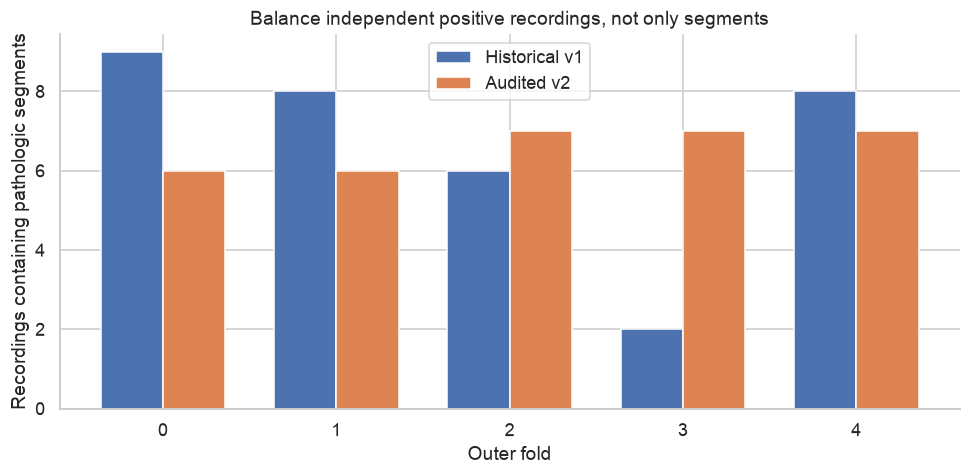

In [9]:
support=pd.read_csv(AUDIT/'outer_fold_support.csv')
display(support)
old=pd.read_csv(ROOT/'research/experiments/ctg_uci/outer_folds.csv').merge(data[['source_excel_row','source_file','NSP']],on='source_excel_row',validate='one_to_one')
old_counts=old[old.NSP==3].groupby('outer_fold').source_file.nunique()
fig,ax=plt.subplots(figsize=(9,4.5));x=np.arange(5)
ax.bar(x-.18,old_counts.reindex(range(5)),.36,label='Historical v1')
ax.bar(x+.18,support.path_files,.36,label='Audited v2')
ax.set(xlabel='Outer fold',ylabel='Recordings containing pathologic segments',title='Balance independent positive recordings, not only segments')
ax.set_xticks(x);ax.legend();fig.tight_layout();show_save('01_fold_support.png')

### Качество всей процедуры на внешних фолдах

Фолды имеют пересекающиеся train: SD не является доверительным интервалом.


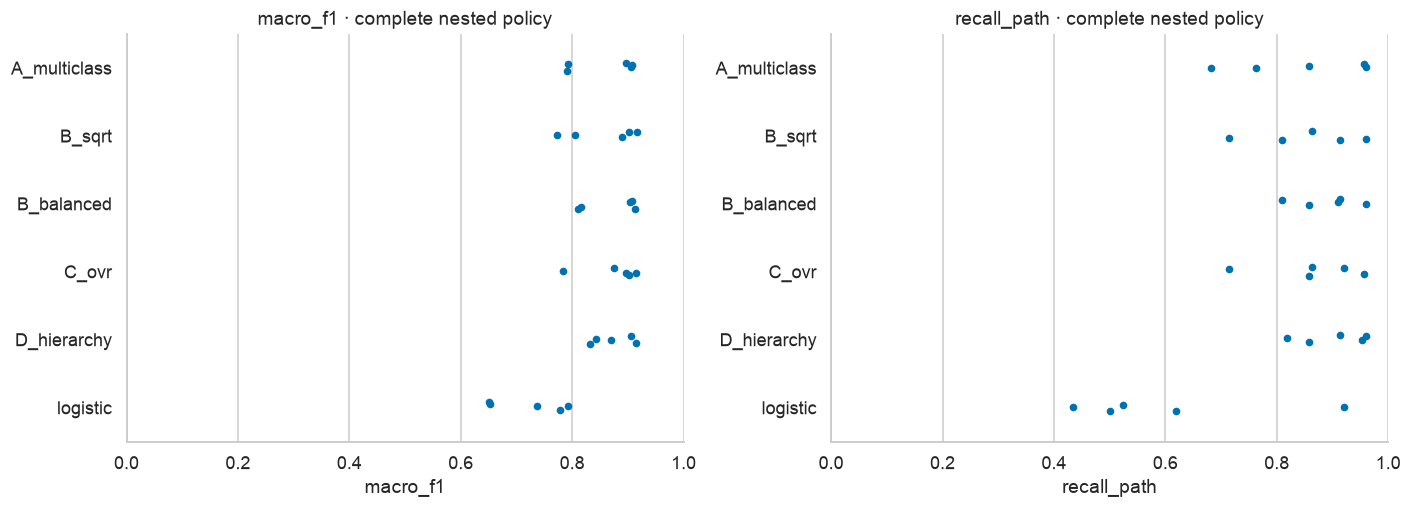

,family,outer_fold,macro_f1,recall_path,file_macro_f1,file_recall_path
0,A_multiclass,0,0.7929,0.6818,0.8326,0.6264
1,B_sqrt,0,0.8042,0.8636,0.8928,0.8959
2,B_balanced,0,0.8108,0.9091,0.8905,0.9251
3,C_ovr,0,0.8755,0.8636,0.8934,0.8595
4,D_hierarchy,0,0.8421,0.8182,0.8997,0.8303
5,logistic,0,0.6527,0.5000,0.6238,0.4203
6,A_multiclass,1,0.9082,0.9600,0.8894,0.9731
7,B_sqrt,1,0.9016,0.9600,0.8946,0.9731
8,B_balanced,1,0.9080,0.9600,0.8902,0.9731
9,C_ovr,1,0.9021,0.9200,0.9055,0.9391


In [11]:
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
for ax,metric in zip(axes,['macro_f1','recall_path']):
    sns.stripplot(data=folds,x=metric,y='family',ax=ax,jitter=.08,color='#0072b2')
    ax.set(xlim=(0,1),title=f'{metric} · complete nested policy',ylabel='')
fig.tight_layout();show_save('02_nested_scores.png')
display(folds[['family','outer_fold','macro_f1','recall_path','file_macro_f1','file_recall_path']].round(4))
print('Фолды имеют пересекающиеся train: SD не является доверительным интервалом.')

## Takeaways

Сравнивается весь алгоритм обучения, а не лучший postprocessing, выбранный после просмотра внешних результатов. Shortlist и параметры сохраняются до test; утверждение о единственном универсальном победителе не делается.